# Text Analyzer
**Askatbek** · CS 250 Final Project · Fall 2026

*Pitch: "Is my text too long, too repetitive, or too slow to start?"*

The program reads a `.txt` file (an essay or a video script), counts words and sentences,
estimates speaking time, finds the most common words, draws a bar chart, and gives simple tips.

## 1. Imports and settings

In [1]:
import math
import matplotlib.pyplot as plt

# Small words we do not want in the "top words" list (a set is fast for "is it in?" checks)
STOP_WORDS = {"the", "a", "an", "and", "or", "but", "is", "are", "was", "were",
              "to", "of", "in", "on", "at", "for", "with", "it", "this", "that",
              "i", "you", "he", "she", "we", "they", "my", "be", "as", "by", "so",
              "than", "may", "from", "about", "when", "has", "have", "there",
              "not", "if", "can", "will", "our", "your", "us", "me", "one"}

# My own rules of thumb for the tips (you can change them)
MAX_REPEAT = 0.05         # one word should not be more than 5% of all words
MAX_FIRST_SENTENCE = 25   # the first sentence should not be longer than 25 words

## 2. Functions (each one has a single job)

In [2]:
def read_text(filename):
    """Read a text file and return its content as one string.
    Return an empty string if the file does not exist."""
    try:
        with open(filename, "r", encoding="utf-8") as file:
            return file.read()
    except FileNotFoundError:
        print(f"File '{filename}' was not found.")
        return ""


def clean_words(text):
    """Return a list of lowercase words without punctuation at the edges."""
    words = [word.strip(".,!?;:\"'()-") for word in text.lower().split()]
    return [word for word in words if word != ""]


def count_sentences(text):
    """Return the number of sentences (the marks . ! ? are counted)."""
    return sum(text.count(mark) for mark in ".!?")


def count_words(words):
    """Return a dictionary {word: how many times it appears}."""
    counts = {}
    for word in words:
        counts[word] = counts.get(word, 0) + 1
    return counts


def top_words(counts, n=10, skip=STOP_WORDS):
    """Return the n most common words as a list of (word, count) tuples.
    Words in the set 'skip' are ignored."""
    items = [(word, number) for word, number in counts.items() if word not in skip]
    items.sort(key=lambda pair: pair[1], reverse=True)
    return items[:n]


def speaking_time(word_count, wpm=150):
    """Return speaking time as a tuple (minutes, seconds).
    wpm = words per minute (150 is my assumption, you can change it)."""
    total_seconds = math.ceil(word_count / wpm * 60)
    return total_seconds // 60, total_seconds % 60


def get_intro(text, n=30):
    """Return the first n words of the text as one string."""
    return " ".join(text.split()[:n])


def first_sentence_length(text):
    """Return how many words the first sentence has."""
    for i, char in enumerate(text):
        if char in ".!?":
            return len(text[:i].split())
    return len(text.split())


def give_feedback(total_seconds, repeat_share, first_len, max_minutes=5):
    """Return a list of tips: is the text too long, too repetitive, or too slow to start?"""
    tips = []
    if total_seconds > max_minutes * 60:
        tips.append(f"Too long: it takes more than {max_minutes} min to say.")
    if repeat_share > MAX_REPEAT:
        tips.append(f"Repetitive: one word is {repeat_share:.0%} of the whole text.")
    if first_len > MAX_FIRST_SENTENCE:
        tips.append(f"Slow start: the first sentence has {first_len} words.")
    if not tips:
        tips.append("Looks good!")
    return tips


def plot_top_words(top, title="Most common words"):
    """Draw a bar chart of the most common words."""
    names = [word for word, number in top]
    numbers = [number for word, number in top]
    plt.bar(names, numbers)
    plt.title(title)
    plt.xlabel("Word")
    plt.ylabel("Times used")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 3. main(): runs the whole program

In [3]:
def main(filename=None, max_minutes=5):
    """Analyze one text file: print the results, the tips, and draw the graph.
    If no file name is given, ask the user for it."""
    if filename is None:
        filename = input("Text file name (for example sample_good.txt): ")
    text = read_text(filename)
    if text == "":
        return

    words = clean_words(text)
    counts = count_words(words)
    top = top_words(counts)
    minutes, seconds = speaking_time(len(words))
    repeat_share = top[0][1] / len(words) if top else 0
    tips = give_feedback(minutes * 60 + seconds, repeat_share,
                         first_sentence_length(text), max_minutes)

    print(f"===== {filename} =====")
    print(f"Words: {len(words)} | Sentences: {count_sentences(text)}")
    print(f"Speaking time: {minutes} min {seconds} sec")
    print(f"Intro (first 30 words): {get_intro(text)}")
    print("Top words:", top)
    for tip in tips:
        print("Tip:", tip)
    plot_top_words(top, f"Most common words: {filename}")

## 4. Tests (an error here means a function is broken)

In [4]:
assert clean_words("Hello, World!") == ["hello", "world"]
assert clean_words("...") == []
assert count_sentences("Hi. Yes! Ok?") == 3
assert count_words(["a", "b", "a"]) == {"a": 2, "b": 1}
assert top_words({"the": 5, "cat": 3, "dog": 1}, n=1) == [("cat", 3)]   # "the" is skipped
assert speaking_time(150) == (1, 0)
assert speaking_time(0) == (0, 0)
assert get_intro("a b c d", 2) == "a b"
assert first_sentence_length("One two three. Four.") == 3
assert give_feedback(30, 0.01, 5) == ["Looks good!"]
assert read_text("missing_file.txt") == ""
print("All tests passed.")

File 'missing_file.txt' was not found.
All tests passed.


## 5. Results and graphs
First I create two sample texts (so the notebook runs without uploading anything).
One is a short, clear script. The other is a slow and repetitive one.

In [5]:
good = """Space is silent. No sound travels through the empty dark between the stars. Yet it is full of light, heat, and invisible waves. Every star you see is a hot ball of gas, and many are far bigger than our sun. Light from the nearest star takes more than four years to reach us. That means you are looking at the past. Planets circle those stars, and some may have oceans. Scientists use powerful telescopes to search for them. One day, we may find a world much like ours."""

slow = """In this video we are going to talk about space and about the many things in space that people often wonder about when they look up at the sky at night and think about how big space really is. Space is big. Space is very big, and space keeps going and going. When we talk about space, we should remember that space has stars, and space has planets, and space has dark gaps between them. Some people think space is empty, but space is not really empty. Space has dust, space has gas, and space has light. Space is also cold in many places, and space is hot near stars. So when you think about space, think about how much space there is in space. There is a lot of space. Many scientists study space every day because space is full of questions. Thank you for watching this video about space, and see you in the next video about space."""

# Write the two texts to files
for name, content in [("sample_good.txt", good), ("sample_slow.txt", slow)]:
    with open(name, "w", encoding="utf-8") as file:
        file.write(content)

===== sample_good.txt =====
Words: 89 | Sentences: 9
Speaking time: 0 min 36 sec
Intro (first 30 words): Space is silent. No sound travels through the empty dark between the stars. Yet it is full of light, heat, and invisible waves. Every star you see is a hot
Top words: [('stars', 2), ('light', 2), ('star', 2), ('space', 1), ('silent', 1), ('no', 1), ('sound', 1), ('travels', 1), ('through', 1), ('empty', 1)]
Tip: Looks good!


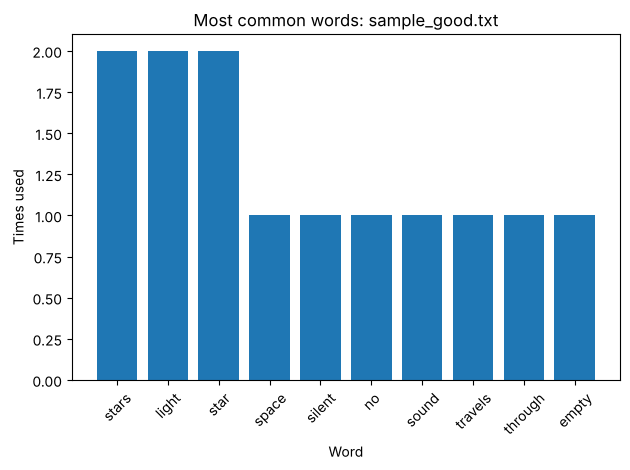

===== sample_slow.txt =====
Words: 160 | Sentences: 11
Speaking time: 1 min 4 sec
Intro (first 30 words): In this video we are going to talk about space and about the many things in space that people often wonder about when they look up at the sky at
Top words: [('space', 25), ('think', 4), ('video', 3), ('going', 3), ('many', 3), ('big', 3), ('talk', 2), ('people', 2), ('how', 2), ('really', 2)]
Tip: Too long: it takes more than 1 min to say.
Tip: Repetitive: one word is 16% of the whole text.
Tip: Slow start: the first sentence has 39 words.


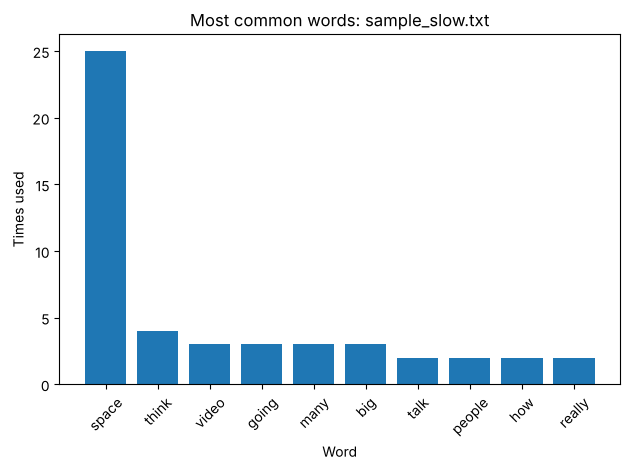

In [6]:
# Target length: 1 minute (for example, a short video)
main("sample_good.txt", max_minutes=1)
main("sample_slow.txt", max_minutes=1)

**To analyze your own text:** upload a `.txt` file to Colab (Files panel on the left),
then run `main("your_file.txt")`. Run `main()` with no name to type the file name.

## 6. AI log
| # | What I asked | What AI gave me | What I changed / decided |
|---|---|---|---|
| 1 | Ideas for a final project that fit the assignment and my life | A list of ideas (trackers, games, a word puzzle, text tools) | I rejected a delivery earnings tracker, first chose a Wordle-style game, then switched to a Text Analyzer |
| 2 | A proposal for my chosen topic | A draft proposal | I told AI I do not run a channel now, so the "Why I care" text was rewritten to be true |
| 3 | A design: flowchart, function list, notebook outline, pseudocode | A PDF with all four parts | I kept the Text Analyzer topic and decided the text is read from a .txt file |
| 4 | Code for the final project, using only topics from our course, short and easy to explain | The functions, the tests, and the two sample texts in this notebook. AI added `first_sentence_length` and `give_feedback` so the program answers the pitch (too long / repetitive / slow start) | I asked for short code that uses only topics from our course, so I can explain it. I reviewed the assignment requirements and my proposal with AI before the code was written |
| 5 | Check that the code works | AI ran the notebook from top to bottom and checked the numbers by hand | So far I have not changed the code that AI gave me. If I change anything later, I will add it here |